# Лабораторная работа 1. Геометрия суперпозиции и Sparse Autoencoders в Transformer-моделях

## 0. Настройка окружения

In [1]:
import os
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import torch
from transformers import AutoTokenizer, GPTNeoXForCausalLM

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:.6f}")

print("numpy", np.__version__, "| torch", torch.__version__)

numpy 2.5.3 | torch 2.14.0+cpu


# Задание 1. Предел концентрации меры и «паразитное направление» LLM
## 1.1 Синтетический тест: концентрация меры на сфере

In [2]:
def random_cosines(d, M=20_000, rng=rng):
    X = rng.standard_normal((M, d), dtype=np.float32)
    Y = rng.standard_normal((M, d), dtype=np.float32)

    U = X / np.linalg.norm(X, axis=1, keepdims=True)
    V = Y / np.linalg.norm(Y, axis=1, keepdims=True)

    return np.sum(U * V, axis=1).astype(np.float64)

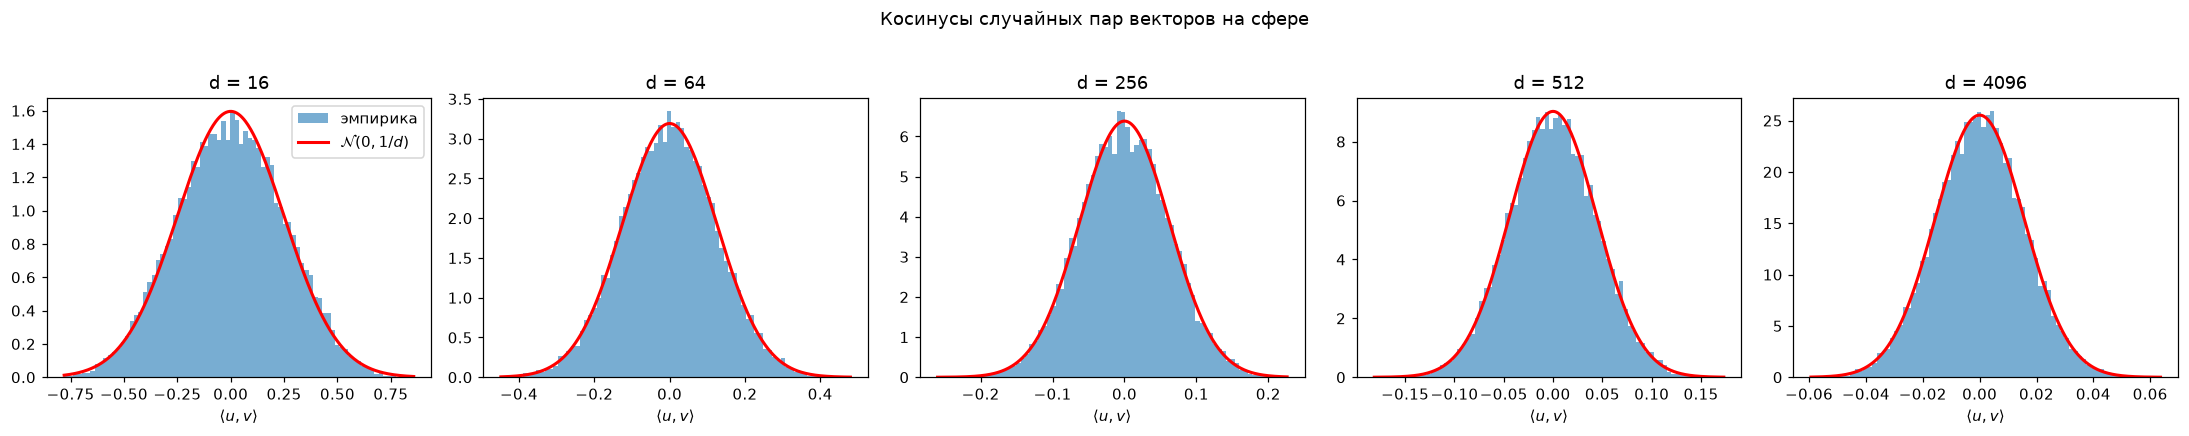

In [3]:
dims = [16, 64, 256, 512, 4096]
cosines = {d: random_cosines(d) for d in dims}

fig, axes = plt.subplots(1, len(dims), figsize=(20, 3.8))
for ax, d in zip(axes, dims):
    s = cosines[d]
    ax.hist(s, bins=80, density=True, alpha=0.6, label="эмпирика")
    grid = np.linspace(s.min(), s.max(), 400)
    ax.plot(grid, stats.norm.pdf(grid, loc=0, scale=1 / np.sqrt(d)), "r-", lw=2, label=r"$\mathcal{N}(0, 1/d)$")
    ax.set_title(f"d = {d}")
    ax.set_xlabel(r"$\langle u, v \rangle$")
axes[0].legend()
plt.suptitle("Косинусы случайных пар векторов на сфере", y=1.03)
plt.tight_layout()
plt.show()

In [4]:
rows = []
for d in dims:
    s = cosines[d]
    rows.append({
        "d": d,
        "σ² теор = 1/d": 1 / d,
        "σ² выборочная": s.var(ddof=1),
        "μ выборочное": s.mean(),
        "эксцесс выборочный": stats.kurtosis(s, fisher=True),
        "эксцесс теор = -6/(d+2)": -6 / (d + 2),
    })
table_synth = pd.DataFrame(rows).set_index("d")
table_synth

,σ² теор = 1/d,σ² выборочная,μ выборочное,эксцесс выборочный,эксцесс теор = -6/(d+2)
d,,,,,
16,0.062500,0.063244,0.001429,-0.311763,-0.333333
64,0.015625,0.015496,-0.000698,-0.070591,-0.090909
256,0.003906,0.003908,-0.000284,-0.057558,-0.023256
512,0.001953,0.001979,-0.000001,-0.022045,-0.011673
4096,0.000244,0.000244,0.000044,0.008255,-0.001464


## 1.2 Эмбеддинги Pythia-70m: «паразитный конус»

In [5]:
MODEL_NAME = "EleutherAI/pythia-70m"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = GPTNeoXForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32)
model.eval()

VOCAB = len(tokenizer)
D_MODEL = model.config.hidden_size

W_in_full = model.gpt_neox.embed_in.weight.detach().numpy().astype(np.float64)
W_in = W_in_full[:VOCAB]

print("размер словаря:", VOCAB, "| d_model:", D_MODEL)
print("полная матрица:", W_in_full.shape, "-> после обрезки:", W_in.shape)
print("связаны ли входные и выходные эмбеддинги (tie_word_embeddings):", model.config.tie_word_embeddings)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

размер словаря: 50277 | d_model: 512
полная матрица: (50304, 512) -> после обрезки: (50277, 512)
связаны ли входные и выходные эмбеддинги (tie_word_embeddings): False


In [ ]:
def normalize_rows(W):
    return W / np.linalg.norm(W, axis=1, keepdims=True)


def sample_pair_cosines(W, n_pairs=10_000, rng=rng):
    U = normalize_rows(W)
    i = rng.integers(0, len(U), n_pairs)
    j = rng.integers(0, len(U), n_pairs)
    keep = i != j
    return np.sum(U[i[keep]] * U[j[keep]], axis=1)


def  (ax, s, d, title):
    ax.hist(s, bins=100, density=True, alpha=0.6, label=f"эмпирика (μ={s.mean():.3f})")
    lo, hi = min(s.min(), -4 / np.sqrt(d)), max(s.max(), 4 / np.sqrt(d))
    grid = np.linspace(lo, hi, 500)
    ax.plot(grid, stats.norm.pdf(grid, 0, 1 / np.sqrt(d)), "r-", lw=2, label=rf"$\mathcal{{N}}(0, 1/{d})$")
    ax.axvline(0, color="k", lw=0.8, ls="--")
    ax.set_title(title)
    ax.set_xlabel(r"$\langle u, v \rangle$")
    ax.legend(fontsize=8)


def cos_stats(s, d):
    return {"μ": s.mean(), "σ²": s.var(ddof=1), "σ² теор = 1/d": 1 / d,
            "σ² / σ²теор": s.var(ddof=1) * d, "эксцесс": stats.kurtosis(s)}

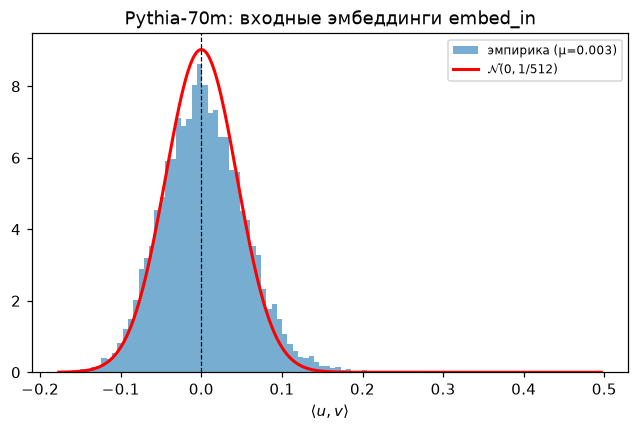

,μ,σ²,σ² теор = 1/d,σ² / σ²теор,эксцесс
embed_in (сырые),0.003341,0.002765,0.001953,1.415925,2.030783


In [7]:
s_in = sample_pair_cosines(W_in)

fig, ax = plt.subplots(figsize=(7, 4))
plot_vs_theory(ax, s_in, D_MODEL, "Pythia-70m: входные эмбеддинги embed_in")
plt.show()

pd.DataFrame([cos_stats(s_in, D_MODEL)], index=["embed_in (сырые)"])

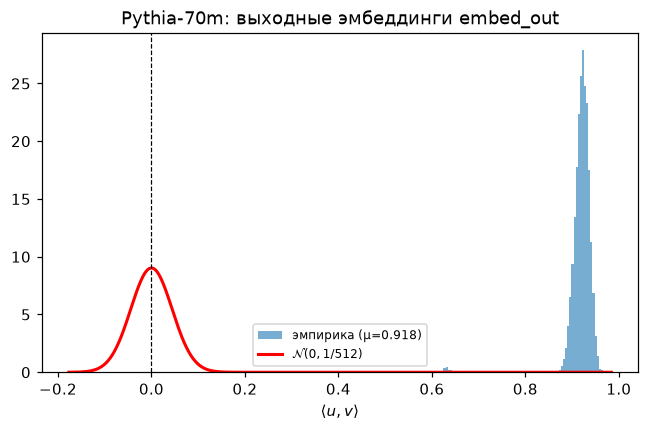

,μ,σ²,σ² теор = 1/d,σ² / σ²теор,эксцесс
embed_in (сырые),0.003341,0.002765,0.001953,1.415925,2.030783
embed_out (сырые),0.918279,0.001153,0.001953,0.590137,60.230901


In [8]:
W_out = model.get_output_embeddings().weight.detach().numpy().astype(np.float64)[:VOCAB]
s_out = sample_pair_cosines(W_out)

fig, ax = plt.subplots(figsize=(7, 4))
plot_vs_theory(ax, s_out, D_MODEL, "Pythia-70m: выходные эмбеддинги embed_out")
plt.show()

pd.DataFrame([cos_stats(s_in, D_MODEL), cos_stats(s_out, D_MODEL)],
             index=["embed_in (сырые)", "embed_out (сырые)"])

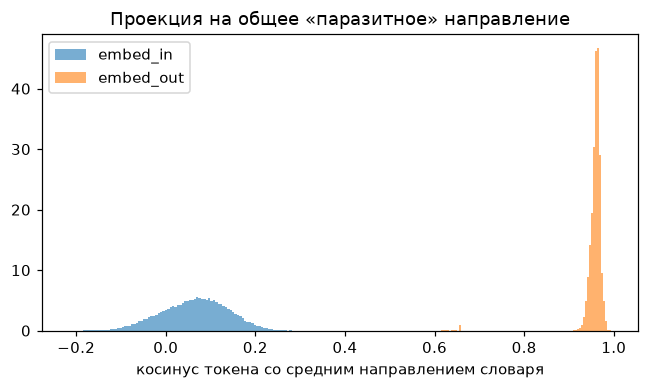

In [9]:
def mean_direction_share(W):
    mean_dir = W.mean(axis=0)
    mean_dir /= np.linalg.norm(mean_dir)
    U = normalize_rows(W)
    return U @ mean_dir

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(mean_direction_share(W_in), bins=100, alpha=0.6, density=True, label="embed_in")
ax.hist(mean_direction_share(W_out), bins=100, alpha=0.6, density=True, label="embed_out")
ax.set_xlabel("косинус токена со средним направлением словаря")
ax.set_title("Проекция на общее «паразитное» направление")
ax.legend()
plt.show()

### Исправление: центрирование и whitening

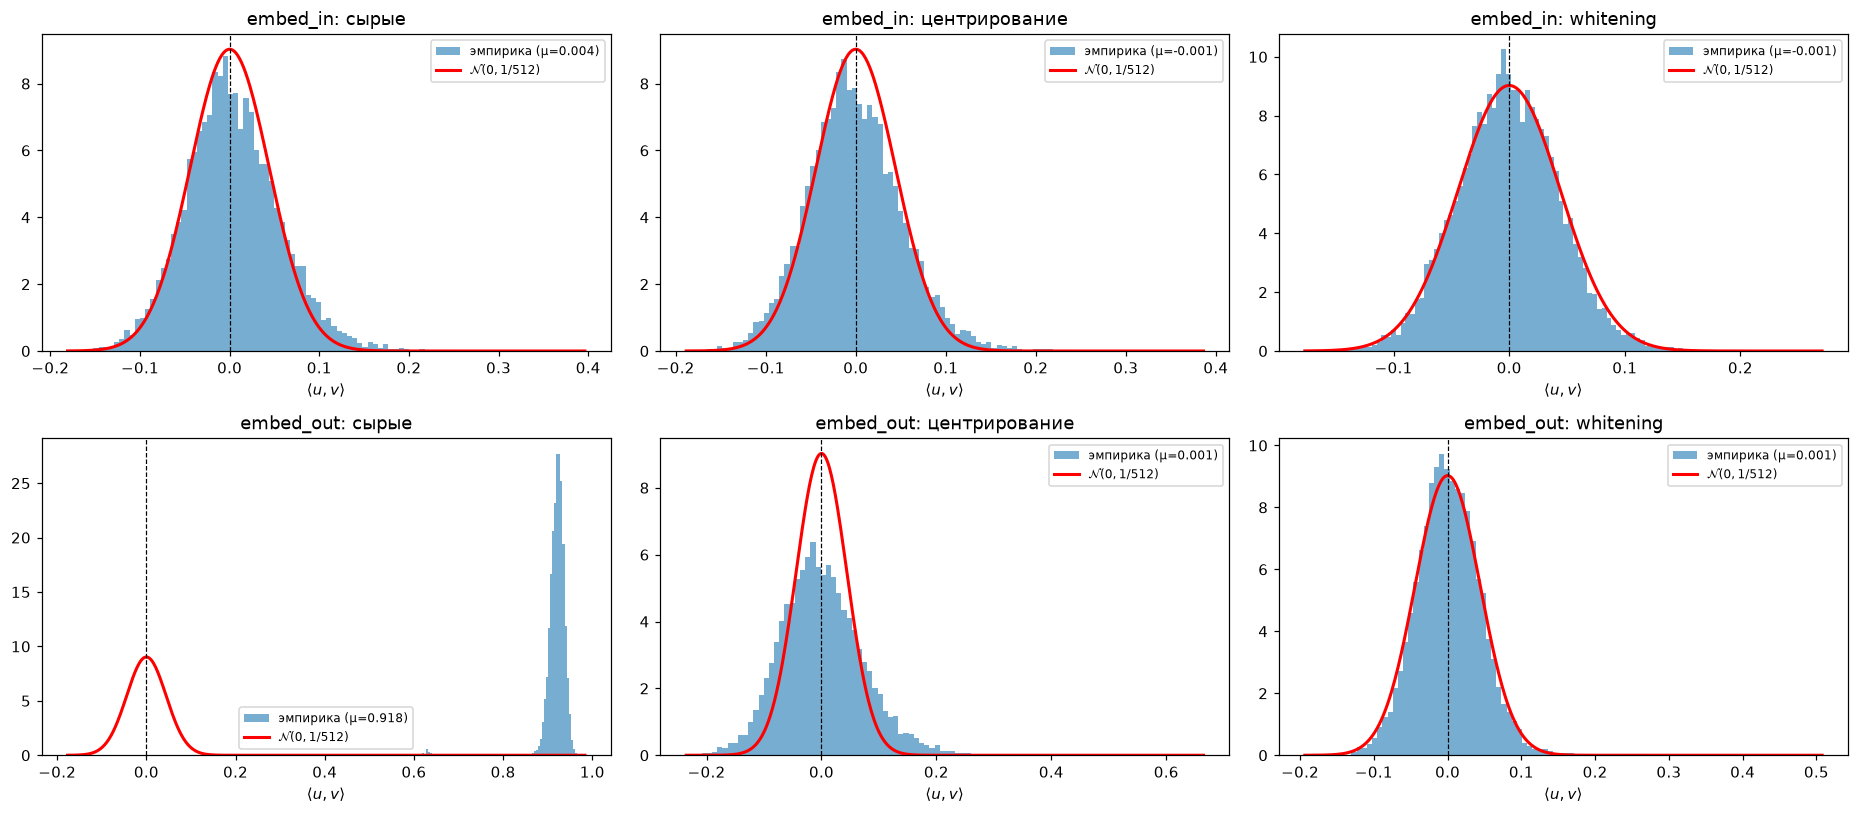

,μ,σ²,σ² теор = 1/d,σ² / σ²теор,эксцесс
embed_in: сырые,0.003718,0.002825,0.001953,1.446294,1.443903
embed_in: центрирование,-0.000628,0.002819,0.001953,1.443293,1.495320
embed_in: whitening,-0.000661,0.001899,0.001953,0.972275,0.409310
embed_out: сырые,0.917705,0.001249,0.001953,0.639489,57.330546
embed_out: центрирование,0.001466,0.005318,0.001953,2.722661,2.223567
embed_out: whitening,0.001250,0.001922,0.001953,0.984289,3.628432


In [10]:
def center(W):
    return W - W.mean(axis=0, keepdims=True)


def whiten(W, eps=1e-8):
    Wc = center(W)
    C = np.cov(Wc, rowvar=False)
    eigval, eigvec = np.linalg.eigh(C)
    C_inv_sqrt = eigvec @ np.diag(1.0 / np.sqrt(eigval + eps)) @ eigvec.T
    return Wc @ C_inv_sqrt


variants = {}
for name, W in [("embed_in", W_in), ("embed_out", W_out)]:
    variants[f"{name}: сырые"] = W
    variants[f"{name}: центрирование"] = center(W)
    variants[f"{name}: whitening"] = whiten(W)

pair_rng = np.random.default_rng(SEED)
i = pair_rng.integers(0, VOCAB, 10_000)
j = pair_rng.integers(0, VOCAB, 10_000)
i, j = i[i != j], j[i != j]

fixed_cos = {}
for name, W in variants.items():
    U = normalize_rows(W)
    fixed_cos[name] = np.sum(U[i] * U[j], axis=1)

fig, axes = plt.subplots(2, 3, figsize=(17, 7.5))
for ax, (name, s) in zip(axes.ravel(), fixed_cos.items()):
    plot_vs_theory(ax, s, D_MODEL, name)
plt.tight_layout()
plt.show()

pd.DataFrame({name: cos_stats(s, D_MODEL) for name, s in fixed_cos.items()}).T

# Задание 2. Toy Model of Superposition: интерференция и геометрия упаковки

## 2.1 Генерация случайной схемы (Random Projection)

In [11]:
d, M = 10, 40
N_TEST = 20_000
p_grid = np.geomspace(0.01, 0.5, 18)

rng2 = np.random.default_rng(SEED)

W_rand = rng2.standard_normal((d, M))
W_rand /= np.linalg.norm(W_rand, axis=0, keepdims=True)
G_rand = W_rand.T @ W_rand

print("W_rand:", W_rand.shape, "| нормы столбцов:", np.round(np.linalg.norm(W_rand, axis=0)[:5], 3), "...")

W_rand: (10, 40) | нормы столбцов: [1. 1. 1. 1. 1.] ...


In [12]:
def generate_features(p, n, rng):
    r = rng.uniform(0, 1, size=(n, M))
    b = rng.random((n, M)) < p
    return r * b


def reconstruct(F, W, b):
    return np.maximum(F @ (W.T @ W) - b, 0)


def nmse(F, F_hat):
    return np.sum((F - F_hat) ** 2, axis=1).mean() / np.sum(F ** 2, axis=1).mean()


test_sets = {p: generate_features(p, N_TEST, rng2) for p in p_grid}

for p in p_grid[[0, 9, -1]]:
    F = test_sets[p]
    print(f"p = {p:.3f}:  доля активных = {(F > 0).mean():.4f},  "
          f"E||f||^2 = {np.sum(F**2, axis=1).mean():.3f}  (теория M*p/3 = {M * p / 3:.3f})")

p = 0.010:  доля активных = 0.0098,  E||f||^2 = 0.130  (теория M*p/3 = 0.133)
p = 0.079:  доля активных = 0.0790,  E||f||^2 = 1.051  (теория M*p/3 = 1.058)
p = 0.500:  доля активных = 0.5003,  E||f||^2 = 6.690  (теория M*p/3 = 6.667)


## 2.2 Поиск оптимального порога фильтрации шума

In [13]:
off_diag = ~np.eye(M, dtype=bool)
relu_G_sq = np.where(off_diag, np.maximum(G_rand, 0) ** 2, 0)
nmse_b0_theory = relu_G_sq.sum(axis=0).mean()

nmse_b0_emp = nmse(test_sets[p_grid[0]], reconstruct(test_sets[p_grid[0]], W_rand, 0.0))
print(f"Оценка (M-1)/(2d)              = {(M - 1) / (2 * d):.3f}")
print(f"Оценка для конкретной W_rand   = {nmse_b0_theory:.3f}")
print(f"Эмпирический NMSE при p=0.01   = {nmse_b0_emp:.3f}")

Оценка (M-1)/(2d)              = 1.950
Оценка для конкретной W_rand   = 1.746
Эмпирический NMSE при p=0.01   = 1.733


In [14]:
b_grid = np.linspace(0, 1, 201)

def find_best_b(F, W, b_grid=b_grid):
    pre = F @ (W.T @ W)
    energy = np.sum(F ** 2, axis=1).mean()
    losses = np.array([np.sum((F - np.maximum(pre - b, 0)) ** 2, axis=1).mean() / energy for b in b_grid])
    k = losses.argmin()
    return b_grid[k], losses[k], losses[0]


rows = []
for p in p_grid:
    b_star, nmse_star, nmse_zero = find_best_b(test_sets[p], W_rand)
    rows.append({"p": p, "b*": b_star, "NMSE(b*)": nmse_star, "NMSE(b=0)": nmse_zero})
res_rand = pd.DataFrame(rows).set_index("p")
res_rand

,b*,NMSE(b*),NMSE(b=0)
p,,,
0.010000,0.305000,0.364451,1.732896
0.012587,0.310000,0.371279,1.730278
0.015845,0.315000,0.392084,1.727055
0.019944,0.320000,0.403924,1.714832
0.025105,0.325000,0.423251,1.711681
0.031601,0.335000,0.450449,1.705419
0.039777,0.345000,0.480766,1.700672
0.050070,0.360000,0.508100,1.686854
0.063025,0.375000,0.543315,1.669622


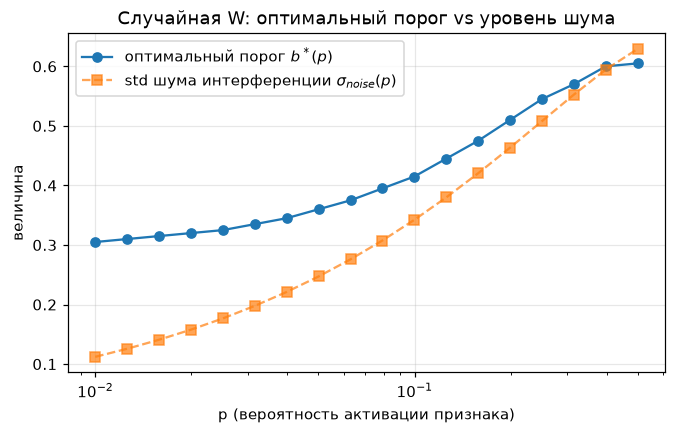

In [15]:
sum_G_sq = np.where(off_diag, G_rand ** 2, 0).sum(axis=1).mean()
noise_std = np.sqrt(sum_G_sq * (p_grid / 3 - p_grid ** 2 / 4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(p_grid, res_rand["b*"], "o-", label=r"оптимальный порог $b^*(p)$")
ax.plot(p_grid, noise_std, "s--", alpha=0.7, label=r"std шума интерференции $\sigma_{noise}(p)$")
ax.set_xscale("log")
ax.set_xlabel("p (вероятность активации признака)")
ax.set_ylabel("величина")
ax.set_title("Случайная W: оптимальный порог vs уровень шума")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 2.3 Фазовая диаграмма и анализ «коллапса»

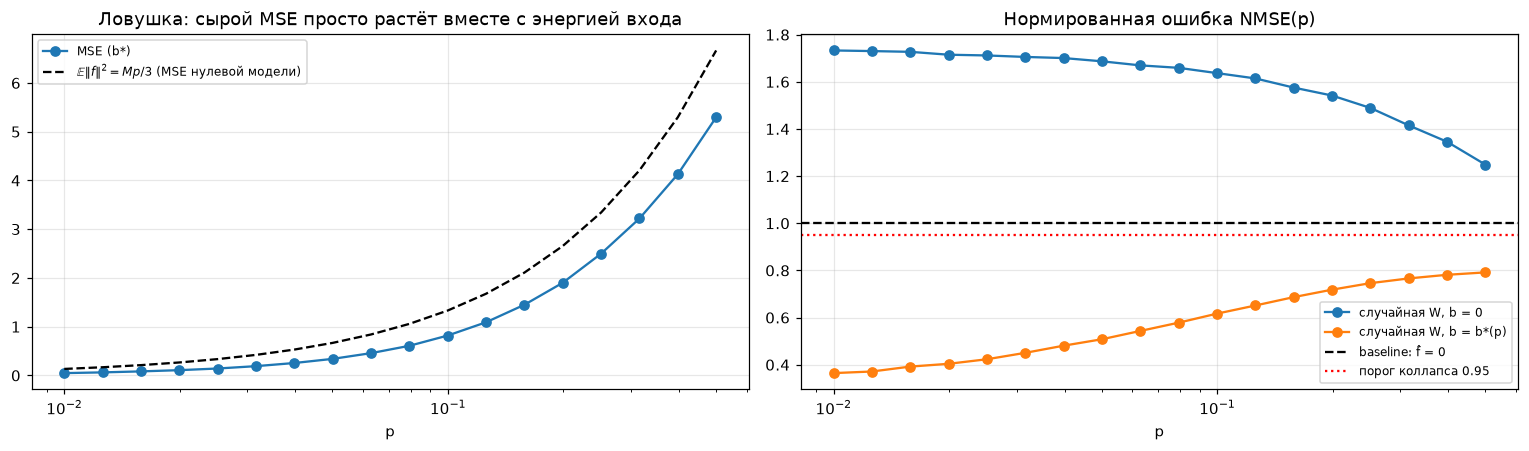

Точка коллапса при b = 0 : 0.01
Точка коллапса при b = b*: None


In [16]:
def find_collapse(ps, nmse_values, threshold=0.95):
    idx = np.where(np.asarray(nmse_values) >= threshold)[0]
    return ps[idx[0]] if len(idx) > 0 else None


raw_mse = [np.sum((F - reconstruct(F, W_rand, res_rand.loc[p, "b*"])) ** 2, axis=1).mean()
           for p, F in test_sets.items()]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(p_grid, raw_mse, "o-", label="MSE (b*)")
axes[0].plot(p_grid, M * p_grid / 3, "k--", label=r"$\mathbb{E}\|f\|^2 = Mp/3$ (MSE нулевой модели)")
axes[0].set_title("Ловушка: сырой MSE просто растёт вместе с энергией входа")

axes[1].plot(p_grid, res_rand["NMSE(b=0)"], "o-", label="случайная W, b = 0")
axes[1].plot(p_grid, res_rand["NMSE(b*)"], "o-", label="случайная W, b = b*(p)")
axes[1].axhline(1.0, color="k", ls="--", label="baseline: f̂ = 0")
axes[1].axhline(0.95, color="r", ls=":", label="порог коллапса 0.95")
axes[1].set_title("Нормированная ошибка NMSE(p)")

for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("p")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Точка коллапса при b = 0 :", find_collapse(p_grid, res_rand["NMSE(b=0)"]))
print("Точка коллапса при b = b*:", find_collapse(p_grid, res_rand["NMSE(b*)"]))

In [17]:
p_dense = np.array([0.6, 0.7, 0.8, 0.9, 1.0])
nmse_dense = [find_best_b(generate_features(p, N_TEST, rng2), W_rand)[1] for p in p_dense]
pd.DataFrame({"p": p_dense, "NMSE(b*)": nmse_dense}).set_index("p").T

p,0.600000,0.700000,0.800000,0.900000,1.000000
NMSE(b*),0.793450,0.792328,0.787170,0.776414,0.765254


## 2.4 «Ловушка случайной матрицы» vs настоящая суперпозиция

In [18]:
def train_toy_model(p, steps=3000, batch_size=1024, lr=1e-2, seed=SEED):
    gen = torch.Generator().manual_seed(seed)

    W = torch.randn(d, M, generator=gen)
    W = W / W.norm(dim=0, keepdim=True)
    W.requires_grad_(True)
    b = torch.zeros(M, requires_grad=True)

    optimizer = torch.optim.Adam([W, b], lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps)

    for step in range(steps):
        f = torch.rand(batch_size, M, generator=gen) * (torch.rand(batch_size, M, generator=gen) < p)

        f_hat = torch.relu(f @ W.T @ W - b)
        loss = ((f - f_hat) ** 2).sum(dim=1).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()

        with torch.no_grad():
            W /= W.norm(dim=0, keepdim=True).clamp(min=1.0)

    return W.detach().numpy().astype(np.float64), b.detach().numpy().astype(np.float64)

In [19]:
import time

trained = {}
t0 = time.time()
for p in p_grid:
    trained[p] = train_toy_model(p)
print(f"Обучено {len(trained)} моделей за {time.time() - t0:.0f} с")

res_rand["NMSE обученная"] = [nmse(test_sets[p], reconstruct(test_sets[p], *trained[p])) for p in p_grid]
res_rand[["NMSE(b=0)", "NMSE(b*)", "NMSE обученная"]]

Обучено 18 моделей за 90 с


,NMSE(b=0),NMSE(b*),NMSE обученная
p,,,
0.010000,1.732896,0.364451,0.116228
0.012587,1.730278,0.371279,0.128664
0.015845,1.727055,0.392084,0.145811
0.019944,1.714832,0.403924,0.154119
0.025105,1.711681,0.423251,0.179590
0.031601,1.705419,0.450449,0.200863
0.039777,1.700672,0.480766,0.222920
0.050070,1.686854,0.508100,0.254515
0.063025,1.669622,0.543315,0.289001


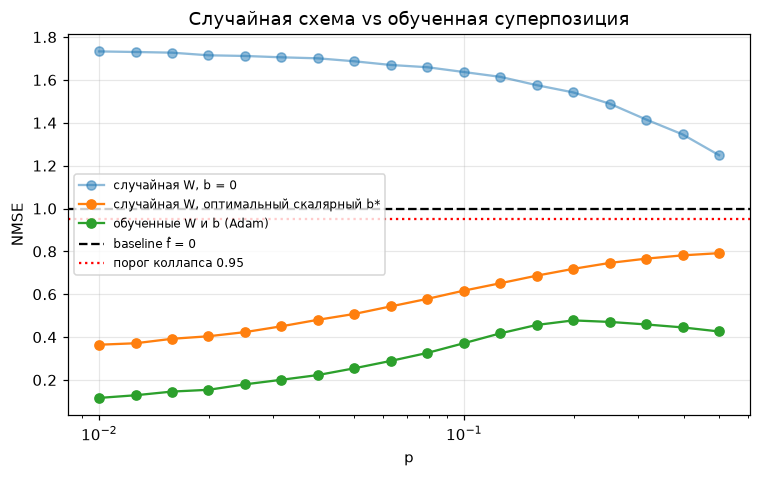

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(p_grid, res_rand["NMSE(b=0)"], "o-", alpha=0.5, label="случайная W, b = 0")
ax.plot(p_grid, res_rand["NMSE(b*)"], "o-", label="случайная W, оптимальный скалярный b*")
ax.plot(p_grid, res_rand["NMSE обученная"], "o-", label="обученные W и b (Adam)")
ax.axhline(1.0, color="k", ls="--", label="baseline f̂ = 0")
ax.axhline(0.95, color="r", ls=":", label="порог коллапса 0.95")
ax.set_xscale("log")
ax.set_xlabel("p")
ax.set_ylabel("NMSE")
ax.set_title("Случайная схема vs обученная суперпозиция")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.show()

### Геометрический анализ: матрица Грама

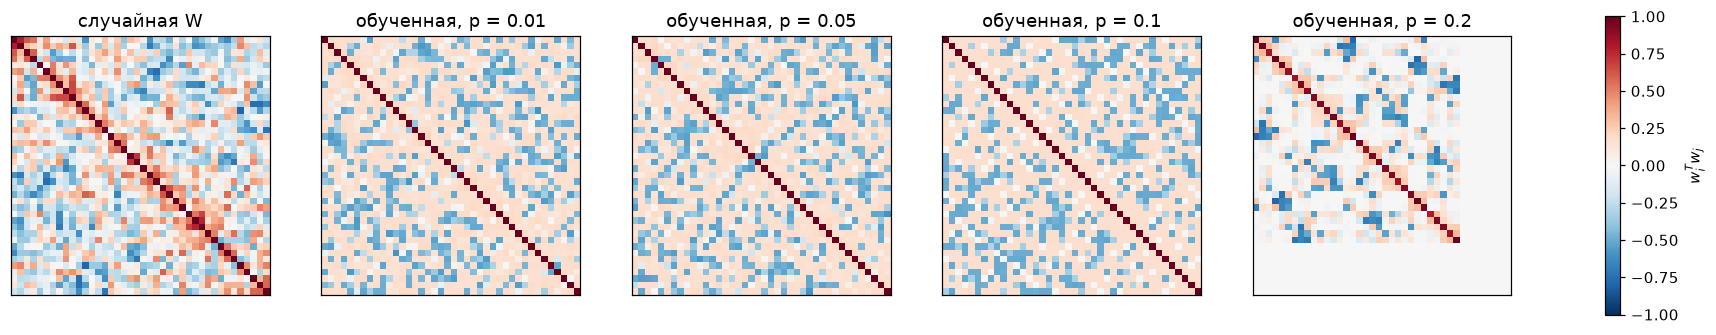

In [21]:
from scipy.cluster.hierarchy import linkage, leaves_list

P_SHOW = [0.01, 0.05, 0.1, 0.2]
trained_show = {p: train_toy_model(p, steps=5000) for p in P_SHOW}


def feature_order(W):
    norms = np.linalg.norm(W, axis=0)
    alive = np.where(norms >= 0.5)[0]
    dead = np.where(norms < 0.5)[0]
    if len(alive) > 2:
        alive = alive[leaves_list(linkage(W[:, alive].T, method="average", metric="cosine"))]
    return np.concatenate([alive, dead])


mats = [("случайная W", W_rand)] + [(f"обученная, p = {p}", trained_show[p][0]) for p in P_SHOW]
fig, axes = plt.subplots(1, 5, figsize=(22, 4.4))
for ax, (title, W) in zip(axes, mats):
    order = feature_order(W)
    G = W.T @ W
    im = ax.imshow(G[np.ix_(order, order)], cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label=r"$w_i^T w_j$")
plt.show()

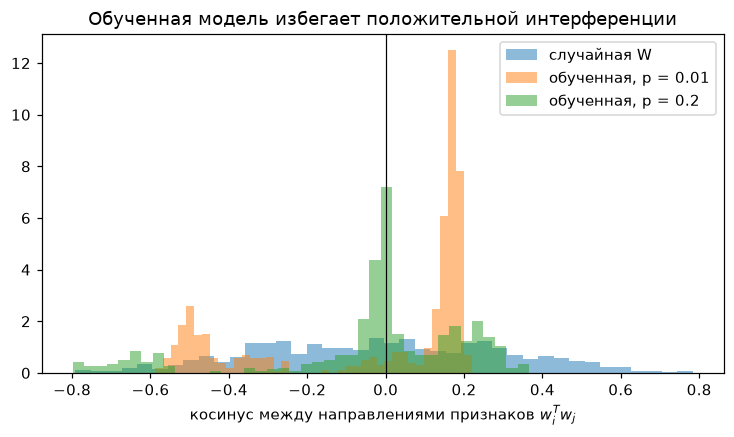

In [22]:
iu = np.triu_indices(M, k=1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(G_rand[iu], bins=40, alpha=0.5, density=True, label="случайная W")
for p in [0.01, 0.2]:
    W = trained_show[p][0]
    alive = np.linalg.norm(W, axis=0) >= 0.5
    U = W[:, alive] / np.linalg.norm(W[:, alive], axis=0)
    ax.hist((U.T @ U)[np.triu_indices(alive.sum(), k=1)], bins=40, alpha=0.5, density=True, label=f"обученная, p = {p}")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel(r"косинус между направлениями признаков $w_i^T w_j$")
ax.set_title("Обученная модель избегает положительной интерференции")
ax.legend()
plt.show()

In [23]:
rows = []
for p in P_SHOW:
    W, b = trained_show[p]
    F = generate_features(p, N_TEST, rng2)
    b_star_rand = find_best_b(F, W_rand)[:2]
    norms = np.linalg.norm(W, axis=0)
    g = (W.T @ W)[iu]
    rows.append({
        "p": p,
        "NMSE случайная (b*)": b_star_rand[1],
        "NMSE обученная": nmse(F, reconstruct(F, W, b)),
        "живых признаков (||w|| ≥ 0.5)": int((norms >= 0.5).sum()),
        "измерений на признак d/||W||²_F": d / np.sum(norms ** 2),
        "max косинус": g.max(),
        "min косинус": g.min(),
        "антиподальных пар (cos < -0.8)": int((g < -0.8).sum()),
        "средний порог b": b.mean(),
    })
g_rand = G_rand[iu]
print(f"Для сравнения, случайная W: max косинус = {g_rand.max():.2f}, min = {g_rand.min():.2f}, "
      f"антиподальных пар = {(g_rand < -0.8).sum()}")
pd.DataFrame(rows).set_index("p")

Для сравнения, случайная W: max косинус = 0.78, min = -0.79, антиподальных пар = 0


,NMSE случайная (b*),NMSE обученная,живых признаков (||w|| ≥ 0.5),измерений на признак d/||W||²_F,max косинус,min косинус,антиподальных пар (cos < -0.8),средний порог b
p,,,,,,,,
0.010000,0.364347,0.109610,40,0.250000,0.219220,-0.589241,0,0.149056
0.050000,0.508053,0.254864,40,0.250000,0.212409,-0.588169,0,0.213645
0.100000,0.618804,0.377772,40,0.250000,0.184082,-0.525125,0,0.259129
0.200000,0.719828,0.475806,32,0.337404,0.332404,-0.793227,0,0.107348


# Задание 3. Взлом и починка Top-K Sparse Autoencoder на активациях Pythia-70m

## 3.1 Датасет активаций

In [24]:
from datasets import load_dataset
import time

LAYER = 3
CTX = 128
N_SEQ = 1050

pile = load_dataset("NeelNanda/pile-10k", split="train")

texts = [t[:3000] for t in pile["text"][:1400]]
token_ids = tokenizer(texts, truncation=True, max_length=CTX)["input_ids"]
token_ids = torch.tensor([ids for ids in token_ids if len(ids) == CTX][:N_SEQ])
print("фрагментов:", token_ids.shape)

фрагментов: torch.Size([1050, 128])


In [25]:
class StopForward(Exception):
    pass


def get_residual(ids, layer=LAYER):
    captured = {}

    def hook(module, inputs, output):
        captured["x"] = output[0] if isinstance(output, tuple) else output
        raise StopForward

    handle = model.gpt_neox.layers[layer].register_forward_hook(hook)
    try:
        with torch.no_grad():
            model.gpt_neox(ids)
    except StopForward:
        pass
    finally:
        handle.remove()
    return captured["x"]


t0 = time.time()
chunks = [get_residual(token_ids[i:i + 32]) for i in range(0, len(token_ids), 32)]
resid = torch.cat(chunks)
print(f"активации: {tuple(resid.shape)}, собраны за {time.time() - t0:.0f} с")

активации: (1050, 128, 512), собраны за 20 с


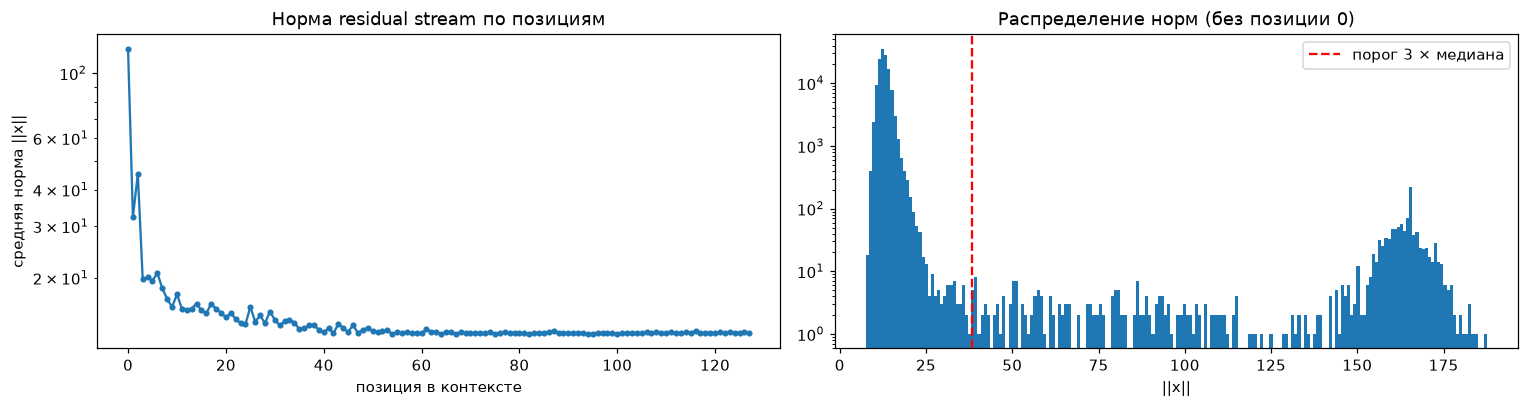

Самые частые токены-выбросы: {'\n': np.int64(581), '.': np.int64(460), '."': np.int64(5), '\n\n': np.int64(4), ' general': np.int64(2), 'The': np.int64(2)}


In [26]:
norms = resid.norm(dim=-1)
median_norm = norms[:, 1:].median()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(norms.mean(dim=0).numpy(), "o-", ms=3)
axes[0].set_yscale("log")
axes[0].set_xlabel("позиция в контексте")
axes[0].set_ylabel("средняя норма ||x||")
axes[0].set_title("Норма residual stream по позициям")
axes[1].hist(norms[:, 1:].flatten().numpy(), bins=200, log=True)
axes[1].axvline(3 * median_norm, color="r", ls="--", label="порог 3 × медиана")
axes[1].set_xlabel("||x||")
axes[1].set_title("Распределение норм (без позиции 0)")
axes[1].legend()
plt.tight_layout()
plt.show()

big = (norms > 3 * median_norm)
big[:, 0] = False
big_tokens = pd.Series([tokenizer.decode([token_ids[b, p]]) for b, p in big.nonzero().tolist()]).value_counts()
print("Самые частые токены-выбросы:", dict(big_tokens.head(6)))

In [27]:
X_all = resid[:, 1:].reshape(-1, D_MODEL)
n_all = X_all.norm(dim=1)
is_massive = n_all > 3 * median_norm

centered = X_all - X_all.mean(dim=0)
share_var = (centered[is_massive] ** 2).sum() / (centered ** 2).sum()
print(f"токенов-выбросов: {is_massive.float().mean():.2%},  их доля в общей дисперсии: {share_var:.1%}")

X = X_all[~is_massive]
perm = torch.randperm(len(X), generator=torch.Generator().manual_seed(SEED))
X = X[perm]

N_STEPS, BATCH = 1000, 64
X_train = X[: N_STEPS * BATCH]
X_test = X[-20_000:]
print("train:", tuple(X_train.shape), "| test:", tuple(X_test.shape))

токенов-выбросов: 0.93%,  их доля в общей дисперсии: 64.3%
train: (64000, 512) | test: (20000, 512)


## 3.2 Исходный (сломанный) автоэнкодер

In [28]:
import torch.nn as nn


class BrokenTopKSAE(nn.Module):
    def __init__(self, d_model=512, d_sae=2048, k=32):
        super().__init__()
        self.k = k
        self.W_enc = nn.Parameter(torch.randn(d_model, d_sae) * 0.02)
        self.b_enc = nn.Parameter(torch.zeros(d_sae))
        self.W_dec = nn.Parameter(torch.randn(d_sae, d_model) * 0.02)
        self.b_dec = nn.Parameter(torch.zeros(d_model))

    def encode(self, x):
        pre_acts = x @ self.W_enc + self.b_enc
        val, idx = torch.topk(pre_acts, self.k, dim=-1)
        acts = torch.zeros_like(pre_acts).scatter_(-1, idx, val)
        return acts

    def decode(self, acts):
        return acts @ self.W_dec + self.b_dec

    def forward(self, x):
        acts = self.encode(x)
        x_hat = self.decode(acts)
        return x_hat, acts

### Метрики и цикл обучения

In [29]:
import math


def explained_variance(x, x_hat):
    return (1 - (x - x_hat).var(dim=1) / x.var(dim=1)).mean().item()


def explained_variance_batch(x, x_hat):
    return 1 - ((x - x_hat).var(dim=0).sum() / x.var(dim=0).sum()).item()


def train_sae(sae, data, n_steps=N_STEPS, batch_size=BATCH, lr=3e-3, window=500):
    optimizer = torch.optim.Adam(sae.parameters(), lr=lr, betas=(0.9, 0.99))
    warmup = 50
    schedule = lambda s: min(1.0, (s + 1) / warmup) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * s / n_steps)))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, schedule)

    fired = torch.zeros(sae.W_enc.shape[1], dtype=torch.bool)
    history = {"ev": [], "ev_batch": [], "dead_so_far": []}
    sae.train()
    t0 = time.time()

    for step in range(n_steps):
        x = data[step * batch_size:(step + 1) * batch_size]
        x_hat, acts = sae(x)

        loss = ((x - x_hat) ** 2).sum(dim=-1).mean()
        if hasattr(sae, "aux_loss"):
            loss = loss + sae.aux_loss(x, x_hat)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        if hasattr(sae, "after_step"):
            sae.after_step()

        with torch.no_grad():
            history["ev"].append(explained_variance(x, x_hat))
            history["ev_batch"].append(explained_variance_batch(x, x_hat))
            if step >= n_steps - window:
                fired |= (acts != 0).any(dim=0)
                history["dead_so_far"].append(1 - fired.float().mean().item())

    return {
        "EV (последние 500 шагов)": np.mean(history["ev"][-window:]),
        "EV по батчу (последние 500 шагов)": np.mean(history["ev_batch"][-window:]),
        "Dead latents (последние 500 шагов)": 1 - fired.float().mean().item(),
        "время обучения, с": time.time() - t0,
    }, history


@torch.no_grad()
def evaluate_sae(sae, data, chunk=2048):
    sae.eval()
    x_hat = torch.cat([sae(data[i:i + chunk])[0] for i in range(0, len(data), chunk)])
    return {"EV на тесте": explained_variance(data, x_hat), "EV по батчу на тесте": explained_variance_batch(data, x_hat)}

In [30]:
torch.manual_seed(SEED)
broken_sae = BrokenTopKSAE()
broken_metrics, broken_hist = train_sae(broken_sae, X_train)
broken_metrics.update(evaluate_sae(broken_sae, X_test))
pd.Series(broken_metrics, name="BrokenTopKSAE").to_frame()

,BrokenTopKSAE
EV (последние 500 шагов),0.771395
EV по батчу (последние 500 шагов),0.654802
Dead latents (последние 500 шагов),0.332520
"время обучения, с",11.472555
EV на тесте,0.781074
EV по батчу на тесте,0.667577


## 3.3 Исправленный Top-K SAE

In [31]:
class TopKSAE(nn.Module):
    def __init__(self, d_model=512, d_sae=2048, k=32, data_mean=None,
                 fix_encode=True, fix_init=True, fix_auxk=True, k_aux=256, dead_steps=50, aux_coef=1 / 32):
        super().__init__()
        self.k, self.k_aux, self.dead_steps, self.aux_coef = k, k_aux, dead_steps, aux_coef
        self.fix_encode, self.fix_init, self.fix_auxk = fix_encode, fix_init, fix_auxk

        if fix_init:
            W_dec = torch.randn(d_sae, d_model)
            W_dec /= W_dec.norm(dim=1, keepdim=True)
            W_enc = W_dec.T.clone()
        else:
            W_dec = torch.randn(d_sae, d_model) * 0.02
            W_enc = torch.randn(d_model, d_sae) * 0.02
        self.W_enc = nn.Parameter(W_enc)
        self.W_dec = nn.Parameter(W_dec)
        self.b_enc = nn.Parameter(torch.zeros(d_sae))
        b_dec = data_mean.clone() if (fix_encode and data_mean is not None) else torch.zeros(d_model)
        self.b_dec = nn.Parameter(b_dec)

        self.register_buffer("steps_since_fired", torch.zeros(d_sae))

    def encode(self, x):
        x_in = x - self.b_dec if self.fix_encode else x
        pre_acts = x_in @ self.W_enc + self.b_enc
        vals, idx = torch.topk(pre_acts, self.k, dim=-1)
        if self.fix_encode:
            vals = torch.relu(vals)
        return pre_acts, vals, idx

    def decode(self, vals, idx):
        return nn.functional.embedding_bag(idx, self.W_dec, per_sample_weights=vals, mode="sum") + self.b_dec

    def forward(self, x):
        pre_acts, vals, idx = self.encode(x)
        x_hat = self.decode(vals, idx)
        acts = torch.zeros_like(pre_acts).scatter(-1, idx, vals)

        if self.training:
            self._pre_acts = pre_acts
            with torch.no_grad():
                self.steps_since_fired += 1
                self.steps_since_fired[idx[vals > 0]] = 0
        return x_hat, acts

    def aux_loss(self, x, x_hat):
        dead = self.steps_since_fired > self.dead_steps
        if not self.fix_auxk or not dead.any():
            return torch.zeros(())
        pre_dead = self._pre_acts.masked_fill(~dead, -float("inf"))
        k_aux = min(self.k_aux, int(dead.sum()))
        vals, idx = torch.topk(pre_dead, k_aux, dim=-1)
        residual = (x - x_hat).detach()
        residual_hat = nn.functional.embedding_bag(idx, self.W_dec, per_sample_weights=torch.relu(vals), mode="sum")
        return self.aux_coef * ((residual - residual_hat) ** 2).sum(dim=-1).mean()

    @torch.no_grad()
    def after_step(self):
        if self.fix_init:
            self.W_dec /= self.W_dec.norm(dim=1, keepdim=True)

In [32]:
data_mean = X_train[:10_000].mean(dim=0)

torch.manual_seed(SEED)
sae = TopKSAE(data_mean=data_mean)
fixed_metrics, fixed_hist = train_sae(sae, X_train)
fixed_metrics.update(evaluate_sae(sae, X_test))

comparison = pd.DataFrame({"BrokenTopKSAE": broken_metrics, "TopKSAE (исправленный)": fixed_metrics})
comparison

,BrokenTopKSAE,TopKSAE (исправленный)
EV (последние 500 шагов),0.771395,0.794113
EV по батчу (последние 500 шагов),0.654802,0.688532
Dead latents (последние 500 шагов),0.332520,0.003906
"время обучения, с",11.472555,19.228007
EV на тесте,0.781074,0.807679
EV по батчу на тесте,0.667577,0.707780


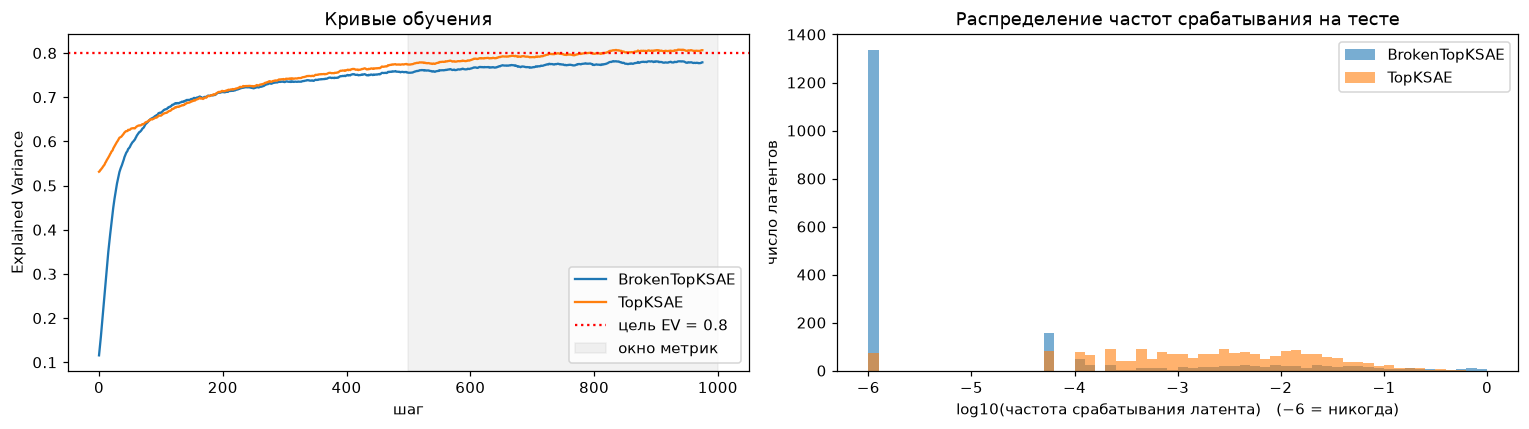

In [33]:
def smooth(values, w=25):
    return np.convolve(values, np.ones(w) / w, mode="valid")


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(smooth(broken_hist["ev"]), label="BrokenTopKSAE")
axes[0].plot(smooth(fixed_hist["ev"]), label="TopKSAE")
axes[0].axhline(0.8, color="r", ls=":", label="цель EV = 0.8")
axes[0].axvspan(N_STEPS - 500, N_STEPS, color="gray", alpha=0.1, label="окно метрик")
axes[0].set_xlabel("шаг")
axes[0].set_ylabel("Explained Variance")
axes[0].set_title("Кривые обучения")
axes[0].legend()

with torch.no_grad():
    broken_sae.eval(); sae.eval()
    freq_broken = (broken_sae(X_test)[1] != 0).float().mean(dim=0)
    freq_fixed = (sae(X_test)[1] != 0).float().mean(dim=0)
bins = np.linspace(-6, 0, 61)
axes[1].hist(np.log10(freq_broken.numpy() + 1e-6), bins=bins, alpha=0.6, label="BrokenTopKSAE")
axes[1].hist(np.log10(freq_fixed.numpy() + 1e-6), bins=bins, alpha=0.6, label="TopKSAE")
axes[1].set_xlabel("log10(частота срабатывания латента)   (−6 = никогда)")
axes[1].set_ylabel("число латентов")
axes[1].set_title("Распределение частот срабатывания на тесте")
axes[1].legend()
plt.tight_layout()
plt.show()

### Абляция: вклад каждого исправления

In [34]:
ablation_configs = {
    "0. как в Broken (ничего не исправлено)": dict(fix_encode=False, fix_init=False, fix_auxk=False),
    "1. + ReLU и центрирование на b_dec":     dict(fix_encode=True,  fix_init=False, fix_auxk=False),
    "2. + единичный декодер, W_enc = W_decᵀ": dict(fix_encode=True,  fix_init=True,  fix_auxk=False),
    "3. + AuxK (полностью исправленная)":     dict(fix_encode=True,  fix_init=True,  fix_auxk=True),
}

ablation = {}
for name, flags in ablation_configs.items():
    torch.manual_seed(SEED)
    model_ab = TopKSAE(data_mean=data_mean, **flags)
    metrics, _ = train_sae(model_ab, X_train)
    metrics.update(evaluate_sae(model_ab, X_test))
    ablation[name] = metrics

pd.DataFrame(ablation).T[["EV (последние 500 шагов)", "EV на тесте", "EV по батчу на тесте", "Dead latents (последние 500 шагов)"]]

,EV (последние 500 шагов),EV на тесте,EV по батчу на тесте,Dead latents (последние 500 шагов)
0. как в Broken (ничего не исправлено),0.769564,0.779695,0.665345,0.330078
1. + ReLU и центрирование на b_dec,0.801244,0.813338,0.716425,0.118652
"2. + единичный декодер, W_enc = W_decᵀ",0.794083,0.807588,0.707711,0.028320
3. + AuxK (полностью исправленная),0.794113,0.807679,0.707780,0.003906


In [35]:
torch.save(sae.state_dict(), "sae_pythia70m_layer3.pt")
print("сохранено: sae_pythia70m_layer3.pt")

сохранено: sae_pythia70m_layer3.pt


# Задание 4. Feature Steering против Neuron Steering

## 4.1 Калибровка шкалы возмущения

In [36]:
neutral_sentences = [
    "The weather today is sunny and warm.",
    "My brother likes to play football on weekends.",
    "The meeting was postponed until next week.",
    "Paris is the capital of France.",
    "She bought apples, bananas and grapes at the market.",
    "The train arrived at the station on time.",
    "Scientists discovered a new species of frog.",
    "The children were playing in the park after school.",
    "He opened the door and walked inside the house.",
    "Music can change the mood of a room.",
    "The book was published in 1998 by a small press.",
    "Water boils at one hundred degrees.",
    "They traveled across the country by car last summer.",
    "The garden was full of roses and tulips.",
    "Our teacher explained the lesson very clearly.",
]

neutral_norms = []
for s in neutral_sentences:
    ids = tokenizer(s, return_tensors="pt").input_ids
    neutral_norms.append(get_residual(ids)[0, 1:].norm(dim=-1))
neutral_norms = torch.cat(neutral_norms)

typical = neutral_norms[neutral_norms < 3 * neutral_norms.median()]
R = typical.mean().item()
print(f"E||x|| (все токены, кроме позиции 0): {neutral_norms.mean():.2f}")
print(f"E||x|| (без выбросов)               : {R:.2f}   <- используем как масштаб R")

alpha_grid = np.round(np.linspace(0.1, 1.5, 15), 2)
ALPHA_LEVELS = {"слабое (0.25R)": 0.25, "среднее (0.5R)": 0.5, "сильное (1.0R)": 1.0}
print("alpha / R:", alpha_grid)

E||x|| (все токены, кроме позиции 0): 31.42
E||x|| (без выбросов)               : 13.42   <- используем как масштаб R
alpha / R: [0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5]


### Хук для стиринга

In [37]:
from contextlib import contextmanager


@contextmanager
def steering(v, alpha, layer=LAYER):
    def hook(module, inputs, output):
        if isinstance(output, tuple):
            return (output[0] + alpha * v,) + tuple(output[1:])
        return output + alpha * v

    handle = model.gpt_neox.layers[layer].register_forward_hook(hook)
    try:
        yield
    finally:
        handle.remove()


PROMPT = "In the middle of the room there was a large table with"


def generate(prompt, v=None, alpha=0.0, n_tokens=25, seed=0, return_ids=False):
    ids = tokenizer(prompt, return_tensors="pt").input_ids
    torch.manual_seed(seed)
    with torch.no_grad(), steering(v if v is not None else torch.zeros(D_MODEL), alpha):
        out = model.generate(ids, max_new_tokens=n_tokens, do_sample=True, top_k=40, temperature=0.8,
                             pad_token_id=tokenizer.eos_token_id)
    new_ids = out[0, ids.shape[1]:]
    return new_ids.tolist() if return_ids else tokenizer.decode(new_ids)


shapes = []
probe = model.gpt_neox.layers[LAYER].register_forward_hook(lambda m, i, o: shapes.append(tuple((o[0] if isinstance(o, tuple) else o).shape)))
generate(PROMPT, n_tokens=4)
probe.remove()
print("формы выхода слоя по шагам генерации:", shapes)

формы выхода слоя по шагам генерации: [(1, 12, 512), (1, 1, 512), (1, 1, 512), (1, 1, 512)]


## 4.2 Эксперимент А: Neuron Steering

In [38]:
NEURON = 42
e_neuron = torch.zeros(D_MODEL)
e_neuron[NEURON] = 1.0

print(f"α = 0      : {generate(PROMPT)!r}")
for c in [0.25, 0.5, 0.75, 1.0, 1.5]:
    print(f"α = {c:<4}·R : {generate(PROMPT, e_neuron, c * R)!r}")

α = 0      : ' a large counter and a table with a large counter. When the front door appeared, the top of the table stood at a'
α = 0.25·R : ' a large iron door and a small table with a large iron lid.\n\nA large and large iron door with a pair'
α = 0.5 ·R : ' a large iron door and a small pocket, which was a small table in the corner. To the floor, a hole was'
α = 0.75·R : ' a large sitting stone and a paper pocket, which was placed on top of the dike and, on the floor, a'
α = 1.0 ·R : ' door-door door-door door-door door-door-door-door door-door door-door door-door'
α = 1.5 ·R : '\ngated on which he he was held,\n\nI\nIn\n\n\n\n\n\n\n\n\n\n\n'


## 4.3 Эксперимент Б: поиск моносемантического латента SAE

In [39]:
probe_sentences = [
    "The function print(x) returns None.", "Call foo(a, b) to compute the sum (see below).",
    "if (x > 0) { return y; }", "The results (shown in Table 2) were significant.",
    "array[0] = compute(value);", "He said (quietly) that it was over.",
    "for (int i = 0; i < n; i++) {", "We used the method of Smith et al. (2019).",
    "def f(x): return g(h(x))", "The cat (a tabby) sat on the mat.", "x = np.zeros((3, 4))",
    "The World Health Organization (WHO) issued a warning.",
    'She replied "I will come tomorrow."', '"Hello," he said, "how are you?"',
    'The sign read "Closed for the season".', 'He shouted "Stop!" and ran.',
    'My mother always says "Never give up."',
    *neutral_sentences[:13],
]


def sae_features(x):
    _, vals, idx = sae.encode(x)
    return torch.zeros(x.shape[0], sae.W_enc.shape[1]).scatter(-1, idx, vals)


rows_tok, feats = [], []
with torch.no_grad():
    for s in probe_sentences:
        ids = tokenizer(s, return_tensors="pt").input_ids
        x = get_residual(ids)[0, 1:]
        feats.append(sae_features(x))
        rows_tok += [tokenizer.decode([t]) for t in ids[0, 1:]]
F_probe = torch.cat(feats)
tok_strings = np.array(rows_tok)
print("токенов в проверочном датасете:", len(tok_strings))

токенов в проверочном датасете: 273


In [40]:
def find_latent(target_tokens, max_neutral_rate=0.01):
    is_target = torch.tensor([t.strip() in target_tokens for t in tok_strings])
    mean_target = F_probe[is_target].mean(dim=0)
    recall = (F_probe[is_target] > 0).float().mean(dim=0)
    neutral_rate = (F_probe[~is_target] > 0).float().mean(dim=0)

    score = mean_target * (neutral_rate <= max_neutral_rate)
    top = score.argsort(descending=True)[:5]
    table = pd.DataFrame({
        "латент j": top.numpy(),
        "E[f_j] на целевых": mean_target[top].numpy(),
        "доля целевых, где активен": recall[top].numpy(),
        "доля остальных, где активен": neutral_rate[top].numpy(),
    })
    return int(top[0]), int(is_target.sum()), table


j_paren, n_paren, table_paren = find_latent({"("})
j_quote, n_quote, table_quote = find_latent({'"'})
print(f"Кандидаты для '(' (целевых токенов: {n_paren}):")
display(table_paren)
print(f"Кандидаты для кавычки (целевых токенов: {n_quote}):")
display(table_quote)

Кандидаты для '(' (целевых токенов: 14):


,латент j,E[f_j] на целевых,"доля целевых, где активен","доля остальных, где активен"
0,1610,1.944527,1.000000,0.007722
1,48,0.315696,0.357143,0.003861
2,1185,0.227637,0.357143,0.007722
3,1350,0.186161,0.071429,0.000000
4,795,0.179641,0.285714,0.007722


Кандидаты для кавычки (целевых токенов: 5):


,латент j,E[f_j] на целевых,"доля целевых, где активен","доля остальных, где активен"
0,813,1.916287,1.000000,0.007463
1,1740,1.364703,0.800000,0.000000
2,1259,0.464165,0.400000,0.000000
3,989,0.356003,0.600000,0.000000
4,264,0.319353,0.600000,0.000000


In [41]:
J = j_paren

with torch.no_grad():
    acts_J = torch.cat([sae_features(resid[i:i + 64].reshape(-1, D_MODEL))[:, J]
                        for i in range(0, len(resid), 64)]).reshape(resid.shape[:2])
acts_J[:, 0] = 0

top_flat = acts_J.flatten().argsort(descending=True)[:10]
rows = []
for t in top_flat.tolist():
    b, p = divmod(t, CTX)
    rows.append({"активация": acts_J[b, p].item(),
                 "контекст": tokenizer.decode(token_ids[b, max(0, p - 10):p]),
                 "токен": tokenizer.decode([token_ids[b, p]])})
top_table = pd.DataFrame(rows)
print(f"Латент {J}: активен на {(acts_J > 0).float().mean():.2%} токенов корпуса; "
      f"максимальная активация {acts_J.max():.2f}")
pd.set_option("display.max_colwidth", 80)
top_table

Латент 1610: активен на 1.19% токенов корпуса; максимальная активация 5.82


,активация,контекст,токен
0,5.816983,el Instituto Nacional de Investigaciones Espaciales,(
1,5.622970,study indicated that the dorsomedial hypothalamic nucleus,(
2,5.614807,"O). Among them all, an optical coherence tomography",(
3,5.612922,the effects of latent TGF-β binding protein 4,(
4,5.579376,responses to 14 and 16 peptides in human leukocyte antigen,(
5,5.531198,inflammation and increased expression of cyclooxygenase-2,(
6,5.522473,exercise on Ca2+-stimulated adenosine triphosphatase,(
7,5.518921,determine the temporal expression of insulin-like growth factor,(
8,5.470623,Tc-hexamethyl-propyleneamine oxime,(
9,5.451488,canonical peroxisome proliferator-activated receptor gamma,(


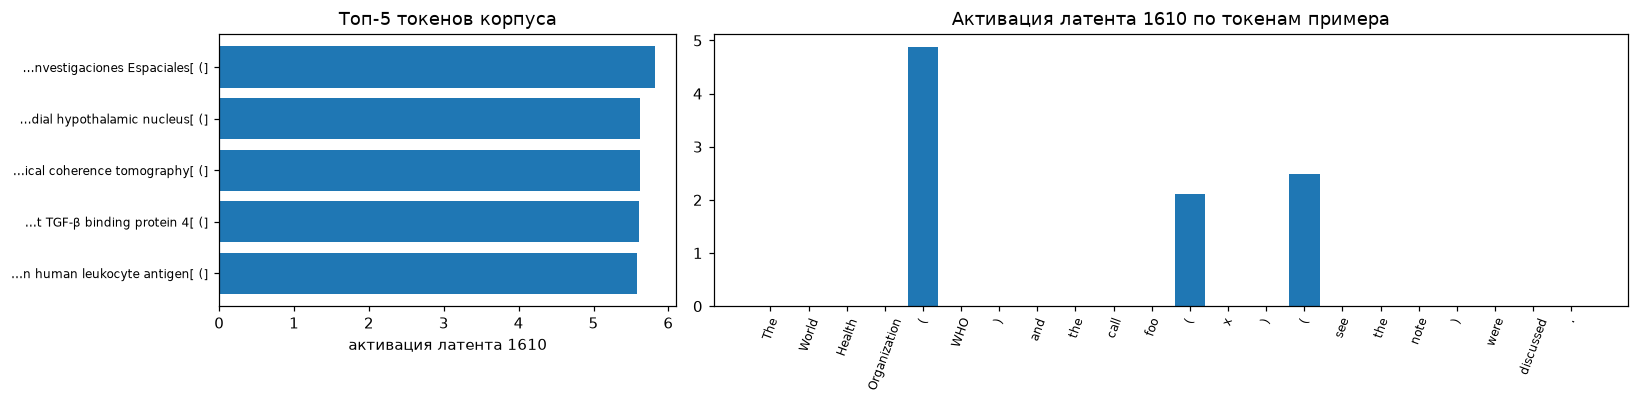

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 2]})

top5 = top_table.head(5)
labels = [f"…{c[-25:]}[{t}]" for c, t in zip(top5["контекст"], top5["токен"])]
axes[0].barh(range(5)[::-1], top5["активация"])
axes[0].set_yticks(range(5)[::-1], labels, fontsize=8)
axes[0].set_xlabel(f"активация латента {J}")
axes[0].set_title("Топ-5 токенов корпуса")

example = "The World Health Organization (WHO) and the call foo(x) (see the note) were discussed."
ids = tokenizer(example, return_tensors="pt").input_ids
with torch.no_grad():
    a = sae_features(get_residual(ids)[0])[:, J].numpy()
a[0] = 0
axes[1].bar(range(len(a)), a)
axes[1].set_xticks(range(len(a)), [tokenizer.decode([t]) for t in ids[0]], rotation=70, fontsize=8)
axes[1].set_title(f"Активация латента {J} по токенам примера")
plt.tight_layout()
plt.show()

## 4.4 Эксперимент В: Feature Steering

In [43]:
v_sae = sae.W_dec[J].detach().clone()
v_sae /= v_sae.norm()

print(f"α = 0      : {generate(PROMPT)!r}")
for c in [0.25, 0.5, 0.75, 1.0, 1.5]:
    print(f"α = {c:<4}·R : {generate(PROMPT, v_sae, c * R)!r}")

α = 0      : ' a large counter and a table with a large counter. When the front door appeared, the top of the table stood at a'
α = 0.25·R : ' a large glass door and a small folding door. The light-on began shining in the bright sunlight on the floor. The'
α = 0.5 ·R : 'out-and-upholeholesbholeholeholeholesholeholesholeholesholeholesholeholesholeholesholeholesholes'
α = 0.75·R : 'outoveror2x2x2x2x2x2x2x2x2x2x2x'
α = 1.0 ·R : 'a5sd22k2k2k2k2k2k2k2k2k2k'
α = 1.5 ·R : 'i5or2or2k2k2k2k2k2k2k2kk2k2'


## Отчёт
### 1. Качественный анализ: сравнительная таблица

In [44]:
rows = [{"вмешательство": "базовая модель", "α": "0", "продолжение": generate(PROMPT)}]
for name, v in [(f"нейрон e_{NEURON}", e_neuron), (f"SAE-латент {J}", v_sae)]:
    for level, c in ALPHA_LEVELS.items():
        rows.append({"вмешательство": name, "α": f"{level}, α = {c * R:.1f}", "продолжение": generate(PROMPT, v, c * R)})

pd.set_option("display.max_colwidth", 200)
pd.DataFrame(rows).style.set_properties(**{"text-align": "left"})

,вмешательство,α,продолжение
0,базовая модель,0,"a large counter and a table with a large counter. When the front door appeared, the top of the table stood at a"
1,нейрон e_42,"слабое (0.25R), α = 3.4",a large iron door and a small table with a large iron lid. A large and large iron door with a pair
2,нейрон e_42,"среднее (0.5R), α = 6.7","a large iron door and a small pocket, which was a small table in the corner. To the floor, a hole was"
3,нейрон e_42,"сильное (1.0R), α = 13.4",door-door door-door door-door door-door-door-door door-door door-door door-door
4,SAE-латент 1610,"слабое (0.25R), α = 3.4",a large glass door and a small folding door. The light-on began shining in the bright sunlight on the floor. The
5,SAE-латент 1610,"среднее (0.5R), α = 6.7",out-and-upholeholesbholeholeholeholesholeholesholeholesholeholesholeholesholeholesholeholesholes
6,SAE-латент 1610,"сильное (1.0R), α = 13.4",a5sd22k2k2k2k2k2k2k2k2k2k


### 2. Количественный анализ: LM loss от α

In [45]:
import re

ce_texts = [t[:2000] for t in pile["text"][9000:9200]]
ce_ids = [ids for ids in tokenizer(ce_texts, truncation=True, max_length=64)["input_ids"] if len(ids) == 64]
ce_ids = torch.tensor(ce_ids[:48])

vocab_strings = [tokenizer.decode([t]).strip() for t in range(VOCAB)]
is_acronym = torch.tensor([bool(re.fullmatch(r"[A-Z][A-Z0-9]+", s)) for s in vocab_strings]
                          + [False] * (model.config.vocab_size - VOCAB))
print("токенов-аббревиатур в словаре:", int(is_acronym.sum()))


def lm_metrics(v, alpha):
    with torch.no_grad(), steering(v, alpha):
        out = model(ce_ids, labels=ce_ids)
    probs = out.logits.softmax(dim=-1)
    return out.loss.item(), probs[..., is_acronym].sum(dim=-1).mean().item()


gen_rand = torch.Generator().manual_seed(SEED)
v_random = torch.randn(D_MODEL, generator=gen_rand)
v_random /= v_random.norm()
e128 = torch.zeros(D_MODEL); e128[128] = 1.0
e156 = torch.zeros(D_MODEL); e156[156] = 1.0

directions = {f"нейрон e_{NEURON}": e_neuron, "нейрон e_128": e128, f"SAE-латент {J}": v_sae,
              "случайное направление": v_random, "нейрон e_156 (rogue dim)": e156}
alphas_ce = np.concatenate([[0.0], alpha_grid])

ce_results = {name: [lm_metrics(v, c * R) for c in alphas_ce] for name, v in directions.items()}
ce_table = pd.DataFrame({name: [r[0] for r in res] for name, res in ce_results.items()}, index=alphas_ce)
ce_table.index.name = "α / R"
ce_table.round(2)

токенов-аббревиатур в словаре: 2958


,нейрон e_42,нейрон e_128,SAE-латент 1610,случайное направление,нейрон e_156 (rogue dim)
α / R,,,,,
0.000000,3.500000,3.500000,3.500000,3.500000,3.500000
0.100000,3.520000,3.530000,3.550000,3.540000,3.510000
0.200000,3.600000,3.590000,3.690000,3.630000,3.520000
0.300000,3.740000,3.700000,4.000000,3.790000,3.540000
0.400000,3.920000,3.840000,4.620000,4.010000,3.580000
0.500000,4.160000,4.030000,5.650000,4.290000,3.620000
0.600000,4.430000,4.260000,6.940000,4.620000,3.670000
0.700000,4.710000,4.510000,8.220000,4.990000,3.730000
0.800000,5.010000,4.790000,9.370000,5.370000,3.790000


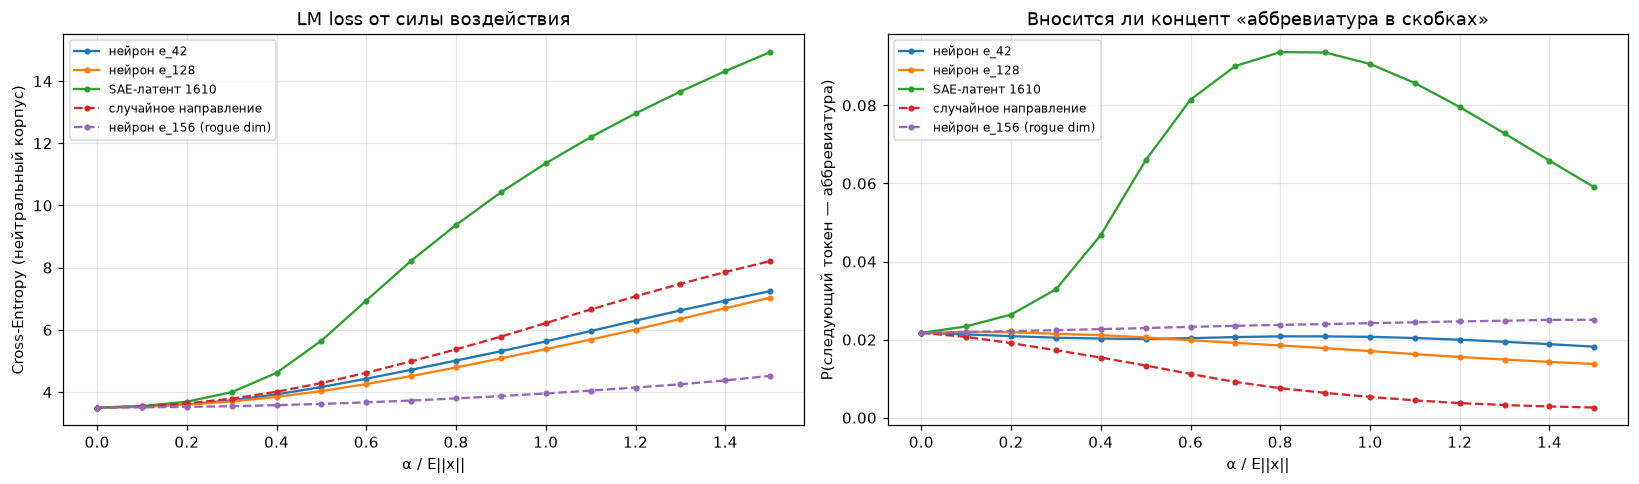

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, res in ce_results.items():
    style = "--" if "rogue" in name or "случайное" in name else "-"
    axes[0].plot(alphas_ce, [r[0] for r in res], style, marker="o", ms=3, label=name)
    axes[1].plot(alphas_ce, [r[1] for r in res], style, marker="o", ms=3, label=name)
axes[0].set_ylabel("Cross-Entropy (нейтральный корпус)")
axes[0].set_title("LM loss от силы воздействия")
axes[1].set_ylabel("P(следующий токен — аббревиатура)")
axes[1].set_title("Вносится ли концепт «аббревиатура в скобках»")
for ax in axes:
    ax.set_xlabel("α / E||x||")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 3. Фазовый переход в бред

нейрон e_42: порог перехода в бред α/R = 1.1  (α = 14.8)
SAE-латент 1610: порог перехода в бред α/R = 0.5  (α = 6.7)


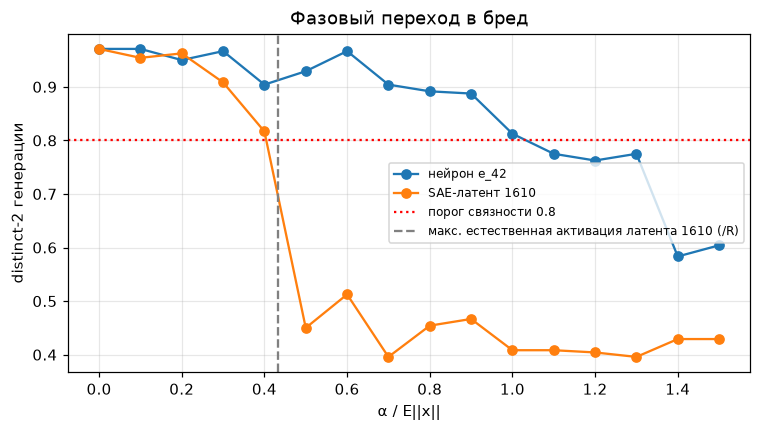

In [47]:
phase_prompts = [PROMPT, "The weather this morning was", "My favourite place in the city is",
                 "After dinner we decided to", "The old man looked at the river and"]


def distinct2(ids):
    bigrams = list(zip(ids, ids[1:]))
    return len(set(bigrams)) / max(1, len(bigrams))


def coherence(v, alpha):
    scores = [distinct2(generate(p, v, alpha, seed=s, return_ids=True)) for p in phase_prompts for s in range(2)]
    return np.mean(scores)


phase = pd.DataFrame({name: [coherence(v, c * R) for c in alphas_ce]
                      for name, v in [(f"нейрон e_{NEURON}", e_neuron), (f"SAE-латент {J}", v_sae)]},
                     index=alphas_ce)
phase.index.name = "α / R"

for name in phase.columns:
    below = phase.index[phase[name] < 0.8]
    thr = below[0] if len(below) else None
    print(f"{name}: порог перехода в бред α/R = {thr}" + (f"  (α = {thr * R:.1f})" if thr is not None else ""))

fig, ax = plt.subplots(figsize=(8, 4))
for name in phase.columns:
    ax.plot(phase.index, phase[name], "o-", label=name)
ax.axhline(0.8, color="r", ls=":", label="порог связности 0.8")
ax.axvline(acts_J.max().item() / R, color="gray", ls="--",
           label=f"макс. естественная активация латента {J} (/R)")
ax.set_xlabel("α / E||x||")
ax.set_ylabel("distinct-2 генерации")
ax.set_title("Фазовый переход в бред")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.show()